# PM2.5 Spatiotemporal Prediction: London

## Set-Up

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")

try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False

try:
    import catboost as cb
    HAS_CB = True
except ImportError:
    HAS_CB = False

RANDOM_STATE = 42
DATA_PATH = "MainData.csv"


In [4]:
print(HAS_XGB)
print(HAS_LGB)
print(HAS_CB)

True
True
True


In [5]:
# Column names, matched to the actual dataset.
TARGET = "pm25"
TIME_COL = "datetime"
STATION_COL = "sensor_id"

CONTINUOUS_FEATURES = [
    "temperature", "rainfall", "humidity", "wind_speed",
    "solar_irradiance", "NDVI_real_corrected",
    "nearest_traffic_aadf", "traffic_distance_m",
    "road_length_250m", "major_road_length_250m",
    "dist_to_nearest_station_m",
]

BINARY_FEATURES = [
    "is_weekend", "is_public_holiday",
    "landcover_group_Built-up_corrected",
    "landcover_group_Green/open space_corrected",
    "landcover_group_Tree cover_corrected",
]

# day_of_week is handled specially per model family (ordinal for trees,
# cyclically encoded for the MLP) rather than included directly here.
CATEGORICAL_FEATURES = ["day_of_week"]

# traffic_volume_hourly_est and traffic_volume_hourly_est_v2 are both
# excluded from the feature set due to data-leakage concerns.

ALL_BASE_FEATURES = CONTINUOUS_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES


## Data Loading

In [7]:
def load_data(path: str = DATA_PATH) -> pd.DataFrame:
    df = pd.read_csv(path, parse_dates=[TIME_COL])
    missing = [c for c in ALL_BASE_FEATURES + [TARGET, STATION_COL] if c not in df.columns]
    if missing:
        raise ValueError(f"Columns not found in data — check names: {missing}")
    return df

df = load_data()
df.shape


(1977329, 64)

## Datetime Handling and Calendar Feature Derivation

In [9]:
# Confirm datetime dtype (re-parse defensively in case the file was loaded
# without parse_dates elsewhere in the workflow).
if not pd.api.types.is_datetime64_any_dtype(df[TIME_COL]):
    df[TIME_COL] = pd.to_datetime(df[TIME_COL])
assert pd.api.types.is_datetime64_any_dtype(df[TIME_COL]), "datetime column failed to parse as a timestamp."

# Derive day_of_week (0=Monday .. 6=Sunday) if not already present.
if "day_of_week" not in df.columns:
    df["day_of_week"] = df[TIME_COL].dt.dayofweek

# Derive is_weekend if not already present.
if "is_weekend" not in df.columns:
    df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

# Derive is_public_holiday if not already present.
if "is_public_holiday" not in df.columns:
    try:
        import holidays as holidays_lib
        years = range(df[TIME_COL].dt.year.min(), df[TIME_COL].dt.year.max() + 1)
        uk_holidays = holidays_lib.UnitedKingdom(years=years)
        holiday_dates = pd.to_datetime(list(uk_holidays.keys()))
        if df[TIME_COL].dt.tz is not None:
            holiday_dates = holiday_dates.tz_localize(df[TIME_COL].dt.tz)
        df["is_public_holiday"] = df[TIME_COL].dt.normalize().isin(holiday_dates).astype(int)
    except ImportError:
        print("The 'holidays' package is not installed — is_public_holiday set to 0 "
              "for all rows. Install with: pip install holidays --break-system-packages")
        df["is_public_holiday"] = 0

df[[TIME_COL, "day_of_week", "is_weekend", "is_public_holiday"]].head()

,datetime,day_of_week,is_weekend,is_public_holiday
0,2020-01-01 00:00:00+00:00,2,0,1
1,2020-01-01 01:00:00+00:00,2,0,1
2,2020-01-01 02:00:00+00:00,2,0,1
3,2020-01-01 03:00:00+00:00,2,0,1
4,2020-01-01 04:00:00+00:00,2,0,1


## Train / Validation / Test Splits

Two split functions are defined, one for each experiment: a temporal split (Experiment A) and a spatial split (Experiment B). They are never combined.


In [11]:
def temporal_split(df: pd.DataFrame):
    """Experiment A: train 2020-2023, validate on 2024, test on 2025.
    All stations appear in every period; only time varies."""
    train = df[df[TIME_COL].dt.year <= 2023].copy()
    val = df[df[TIME_COL].dt.year == 2024].copy()
    test = df[df[TIME_COL].dt.year == 2025].copy()
    assert len(train) and len(val) and len(test), "A temporal split is empty — check year ranges."
    return train, val, test


In [12]:
def spatial_split(df: pd.DataFrame, val_frac: float = 0.15, test_frac: float = 0.15):
    """Experiment B: stations are grouped so that no station appears in more
    than one split. The full time range is used in every split; only
    location varies."""
    stations = df[STATION_COL].unique()
    rng = np.random.RandomState(RANDOM_STATE)
    rng.shuffle(stations)

    n = len(stations)
    n_test = max(1, int(n * test_frac))
    n_val = max(1, int(n * val_frac))

    test_stations = set(stations[:n_test])
    val_stations = set(stations[n_test:n_test + n_val])
    train_stations = set(stations[n_test + n_val:])

    train = df[df[STATION_COL].isin(train_stations)].copy()
    val = df[df[STATION_COL].isin(val_stations)].copy()
    test = df[df[STATION_COL].isin(test_stations)].copy()

    print(f"Spatial split — stations: train={len(train_stations)}, "
          f"val={len(val_stations)}, test={len(test_stations)}")
    return train, val, test


## Preprocessing Classes

Two separate preprocessors are defined: a minimal transformer for tree models and a scaled, encoded transformer for the MLP. Both are fit on the training split only.


In [14]:
class TreePreprocessor:
    """Minimal preprocessing for RF / XGBoost / LightGBM / CatBoost.
    day_of_week is kept as an integer category. Missing values are left as
    NaN for XGBoost/LightGBM/CatBoost, which handle them natively; a
    separate median-imputed copy is produced for Random Forest."""

    def __init__(self):
        self.median_imputer = SimpleImputer(strategy="median")
        self.fitted = False

    def fit(self, train_df: pd.DataFrame):
        self.median_imputer.fit(train_df[CONTINUOUS_FEATURES])
        self.fitted = True
        return self

    def transform(self, df: pd.DataFrame, for_rf: bool = False) -> pd.DataFrame:
        out = df[ALL_BASE_FEATURES].copy()
        if for_rf:
            out[CONTINUOUS_FEATURES] = self.median_imputer.transform(out[CONTINUOUS_FEATURES])
            out[CONTINUOUS_FEATURES] = out[CONTINUOUS_FEATURES].fillna(0)
        return out


In [15]:
class NNPreprocessor:
    """Scaling + imputation + cyclical encoding for the MLP."""

    def __init__(self):
        self.scaler = StandardScaler()
        self.imputer = SimpleImputer(strategy="median")
        self.fitted = False

    def fit(self, train_df: pd.DataFrame):
        imputed = self.imputer.fit_transform(train_df[CONTINUOUS_FEATURES])
        self.scaler.fit(imputed)
        self.fitted = True
        return self

    def transform(self, df: pd.DataFrame) -> pd.DataFrame:
        cont = self.imputer.transform(df[CONTINUOUS_FEATURES])
        cont = self.scaler.transform(cont)
        cont_df = pd.DataFrame(cont, columns=CONTINUOUS_FEATURES, index=df.index)

        binary_df = df[BINARY_FEATURES].fillna(0).astype(float)

        # cyclical encoding for day_of_week (0-6)
        dow = df["day_of_week"].astype(float)
        dow_sin = np.sin(2 * np.pi * dow / 7)
        dow_cos = np.cos(2 * np.pi * dow / 7)
        cyc_df = pd.DataFrame(
            {"day_of_week_sin": dow_sin, "day_of_week_cos": dow_cos}, index=df.index
        )

        return pd.concat([cont_df, binary_df, cyc_df], axis=1)


## Evaluation Metric

Three metrics are computed for every model: RMSE, MAE, and R².

In [20]:
def evaluate(y_true, y_pred) -> dict:
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }


## Model Training and Comparison

The function below fits every available model on the training split, uses
the validation split for early stopping where applicable, and reports final
metrics on the test split. The test split is touched only once, at the end
of training for each model.

In [22]:
def run_experiment(train: pd.DataFrame, val: pd.DataFrame, test: pd.DataFrame,
                    experiment_name: str) -> pd.DataFrame:
    y_train, y_val, y_test = train[TARGET], val[TARGET], test[TARGET]

    tree_prep = TreePreprocessor().fit(train)
    nn_prep = NNPreprocessor().fit(train)

    X_train_tree = tree_prep.transform(train)
    X_val_tree = tree_prep.transform(val)
    X_test_tree = tree_prep.transform(test)

    X_train_rf = tree_prep.transform(train, for_rf=True)
    X_test_rf = tree_prep.transform(test, for_rf=True)

    X_train_nn = nn_prep.transform(train)
    X_test_nn = nn_prep.transform(test)

    results = {}

    # Ridge (baseline)
    ridge = Ridge(alpha=1.0, random_state=RANDOM_STATE)
    ridge.fit(X_train_nn, y_train)
    results["Ridge"] = evaluate(y_test, ridge.predict(X_test_nn))

    # Random Forest
    rf = RandomForestRegressor(
        n_estimators=300, max_depth=None, n_jobs=-1, random_state=RANDOM_STATE,
    )
    rf.fit(X_train_rf, y_train)
    results["RandomForest"] = evaluate(y_test, rf.predict(X_test_rf))

    # XGBoost
    if HAS_XGB:
        xgb_model = xgb.XGBRegressor(
            n_estimators=1000, learning_rate=0.03, max_depth=8,
            subsample=0.8, colsample_bytree=0.8,
            random_state=RANDOM_STATE, early_stopping_rounds=50,
            eval_metric="rmse", n_jobs=-1,
        )
        xgb_model.fit(X_train_tree, y_train, eval_set=[(X_val_tree, y_val)], verbose=False)
        results["XGBoost"] = evaluate(y_test, xgb_model.predict(X_test_tree))

    # LightGBM
    if HAS_LGB:
        lgb_model = lgb.LGBMRegressor(
            n_estimators=2000, learning_rate=0.03, max_depth=-1,
            num_leaves=63, subsample=0.8, colsample_bytree=0.8,
            random_state=RANDOM_STATE, n_jobs=1,
        )
        lgb_model.fit(
            X_train_tree, y_train,
            eval_set=[(X_val_tree, y_val)],
            callbacks=[lgb.early_stopping(50, verbose=False)],
            categorical_feature=["day_of_week"],
        )
        results["LightGBM"] = evaluate(y_test, lgb_model.predict(X_test_tree))

    # CatBoost
    if HAS_CB:
        cb_model = cb.CatBoostRegressor(
            iterations=2000, learning_rate=0.03, depth=8,
            random_state=RANDOM_STATE, cat_features=["day_of_week"],
            early_stopping_rounds=50, verbose=False,
        )
        cb_model.fit(X_train_tree, y_train, eval_set=(X_val_tree, y_val))
        results["CatBoost"] = evaluate(y_test, cb_model.predict(X_test_tree))

    # MLP
    mlp = MLPRegressor(
        hidden_layer_sizes=(128, 64, 32), activation="relu",
        alpha=1e-4, learning_rate_init=1e-3, max_iter=500,
        early_stopping=True, validation_fraction=0.1,
        random_state=RANDOM_STATE,
    )
    mlp.fit(X_train_nn, y_train)
    results["MLP"] = evaluate(y_test, mlp.predict(X_test_nn))

    results_df = pd.DataFrame(results).T
    results_df.index.name = "model"
    results_df.to_csv(f"results_{experiment_name}.csv")
    print(f"=== {experiment_name} experiment — test set metrics ===")
    print(results_df)

    return results_df


## Comparison Plots

For a given experiment's results, three bar charts are produced side by side:
RMSE, MAE, and R², one bar per model.

In [24]:
def plot_comparison(results_df: pd.DataFrame, experiment_name: str):
    metrics = ["RMSE", "MAE", "R2"]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for ax, metric in zip(axes, metrics):
        vals = results_df[metric].sort_values(ascending=(metric != "R2"))
        colors = plt.cm.viridis(np.linspace(0.2, 0.85, len(vals)))
        ax.bar(vals.index, vals.values, color=colors)
        ax.set_title(metric)
        ax.set_ylabel(metric)
        ax.tick_params(axis="x", rotation=45)
    fig.suptitle(f"Model comparison — {experiment_name} test set")
    fig.tight_layout()
    fig.savefig(f"model_comparison_{experiment_name}.png", dpi=150)
    plt.show()


## Experiment A: Temporal Generalization

Train on 2020–2023, validate on 2024, test on 2025.

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.038516 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2266
[LightGBM] [Info] Number of data points in the train set: 1044462, number of used features: 17
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Start training from score 9.475155
=== temporal experiment — test set metrics ===
                   RMSE       MAE        R2
model                                      
Ridge         10.700548  7.311609  0.146842
RandomForest  12.682965  8.231021 -0.198557
XGBoost       10.974721  7.574375  0.102562
LightGBM      11.102032  7.671256  0.081620
CatBoost      10.539174  7.217675  0.172381
MLP           12.543890  8.327790 -0.172416


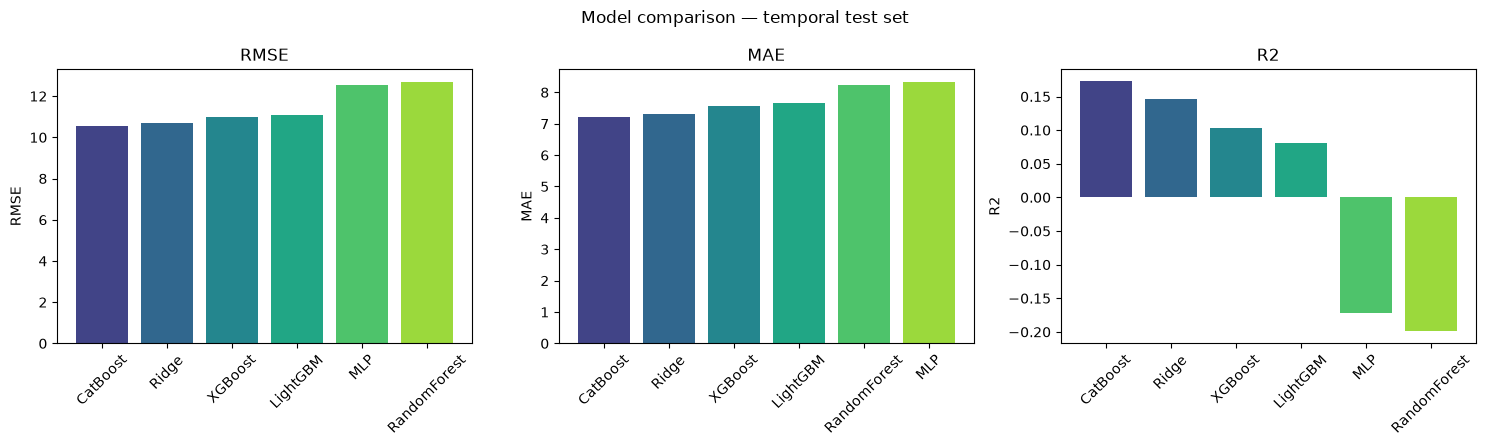

In [26]:
train_t, val_t, test_t = temporal_split(df)
results_temporal = run_experiment(train_t, val_t, test_t, "temporal")
plot_comparison(results_temporal, "temporal")


## Experiment B: Spatial Generalization

Stations are split into disjoint train/validation/test groups so that no
station appears in more than one split.

Spatial split — stations: train=169, val=35, test=35
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.058511 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2341
[LightGBM] [Info] Number of data points in the train set: 1402310, number of used features: 17
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Start training from score 10.514187
=== spatial experiment — test set metrics ===
                  RMSE       MAE        R2
model                                     
Ridge         9.391180  6.248833  0.128507
RandomForest  7.481772  4.621072  0.446863
XGBoost       7.983961  5.157123  0.370116
LightGBM      7.972686  5.167493  0.371894
CatBoost      8.358548  5.477933  0.309625
MLP           8.976745  5.75210

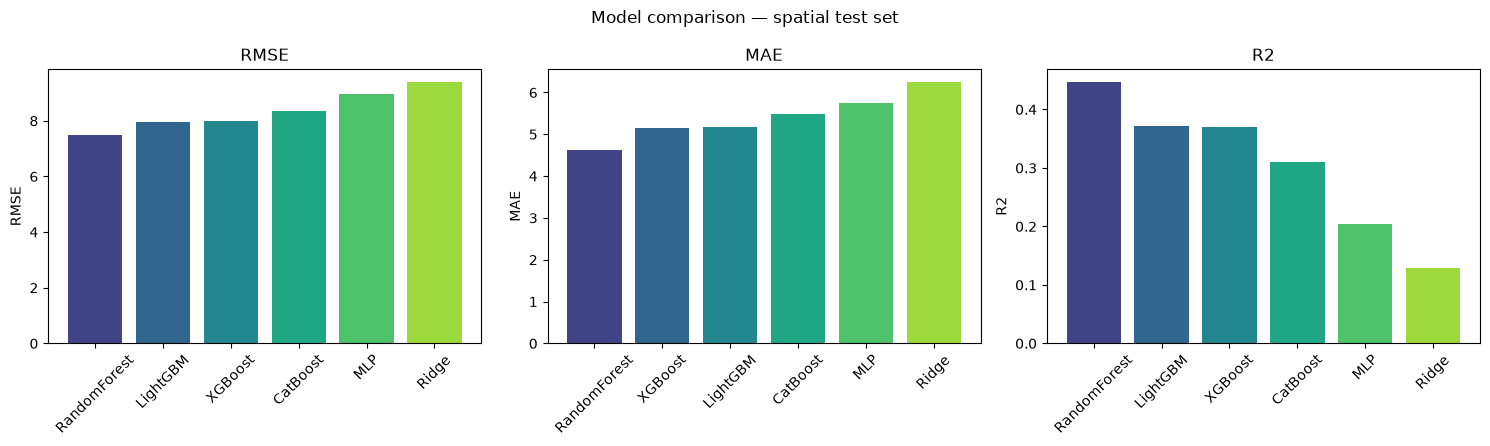

In [28]:
train_s, val_s, test_s = spatial_split(df)
results_spatial = run_experiment(train_s, val_s, test_s, "spatial")
plot_comparison(results_spatial, "spatial")


## Combined Summary

In [30]:
summary = pd.concat(
    {"temporal": results_temporal, "spatial": results_spatial},
    names=["experiment"]
)
summary


RMSE       MAE        R2
experiment model                                      
temporal   Ridge         10.700548  7.311609  0.146842
           RandomForest  12.682965  8.231021 -0.198557
           XGBoost       10.974721  7.574375  0.102562
           LightGBM      11.102032  7.671256  0.081620
           CatBoost      10.539174  7.217675  0.172381
           MLP           12.543890  8.327790 -0.172416
spatial    Ridge          9.391180  6.248833  0.128507
           RandomForest   7.481772  4.621072  0.446863
           XGBoost        7.983961  5.157123  0.370116
           LightGBM       7.972686  5.167493  0.371894
           CatBoost       8.358548  5.477933  0.309625
           MLP            8.976745  5.752101  0.203728